# Adaptive Destroy-and-Repair VNS with Q-Learning Operator Selection for Multi-Compartment Routing with Reconfigurable Vehicles
**ISE 571 Heuristic Search Methods, KFUPM. Term Project, Group 6:** Maha Abd Elhakeem, Sadia Waseem, Saphiah Bajba
Code: https://github.com/SadiaWaseem/571-Project

This notebook reproduces every result of our IEEE paper. All algorithms live in the `mvrdc/` package of the repository; the notebook only calls them.

| Section | Content |
|---|---|
| 0 | Setup (Colab or local) |
| 1 | The MVRDC problem and benchmark of Masmoudi et al. (2026) [1] |
| 2 | Validation of our implementation against the published solutions |
| 3 | Methods compared |
| 4 | One instance, step by step |
| 5 | Experiment 1: learned *neighborhood* selection (diagnosis) |
| 6 | Experiment 2 (main): learned *operator* selection |
| 7 | Parameter sensitivity of the Q-learning policy |
| 8 | Small instances: comparison with the CPLEX optima of [1] |
| 9 | Pros and cons |

The long experiments are switched off by default (`RUN_... = False`). They write one file per run, so a disconnected Colab session resumes where it stopped. Until they are run, Sections 5–7 show the stored pilot results that ship with the repository.

## 0. Setup

In [1]:
import os, sys
REPO_URL = "https://github.com/SadiaWaseem/571-Project.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/571-Project"):
        !git clone -q $REPO_URL /content/571-Project
    %cd /content/571-Project
    !pip -q install -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.isdir("data/MVRDC/Instances"):
    !bash scripts/fetch_data.sh
sys.path.insert(0, os.getcwd())
DATA = "data/MVRDC"
print("working directory:", os.getcwd())

working directory: /home/claude/mvrdc-qvns


Keep results on Google Drive (recommended for the long experiments) so that they survive a disconnected session.

In [2]:
USE_DRIVE = False
RESULTS_ROOT = "results"
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_ROOT = "/content/drive/MyDrive/ISE571-QVNS/results"
os.makedirs(RESULTS_ROOT, exist_ok=True)
print("results are written to", RESULTS_ROOT)

results are written to results


In [3]:
import glob, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mvrdc.instance import load_instance, list_instances
from mvrdc.selectors import make_selector, OPS_ALGORITHMS
from mvrdc.operators import operator_shaking, OP_NAMES
from mvrdc.vns import VNSConfig, solve
from mvrdc import analysis as A, plots as P
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 8})

def run(inst, alg, seconds, seed=1):
    # one run of any method; operator-selection methods use the destroy-and-repair portfolio
    if alg in OPS_ALGORITHMS:
        with operator_shaking():
            return solve(inst, make_selector(alg), VNSConfig(time_limit=seconds), seed)
    return solve(inst, make_selector(alg), VNSConfig(time_limit=seconds), seed)

def results_dir(preferred, fallback):
    ok = lambda d: os.path.isdir(f"{d}/runs") or os.path.exists(f"{d}/runs.zip")
    d = preferred if ok(preferred) else fallback
    print("results from:", d, "(stored pilot)" if d == fallback else "")
    return d

## 1. Problem and data
The MVRDC [1] serves $n$ customers with fresh demand $q^1_i$, frozen demand $q^2_i$ and time window $[e_i,l_i]$ from one depot. The fleet has fresh and frozen single-temperature vehicles, which may carry the other product in frigoboxes of capacity $w$ (at most $F_k$ per vehicle and $F$ at the depot), and mixed-reconfigurable vehicles with $m_k$ predefined fresh/frozen splits. The objective is lexicographic:
$$f(x)=1000\,\#\text{vehicles}+\text{distance}+\theta\,\text{unused space},\qquad \theta=1/\textstyle\sum_i(q^1_i+q^2_i).$$
The benchmark has 15 instances each with 10, 15 and 20 customers, and 60 instances with 200 customers in three fleet classes: A0 (vehicle capacity 150–250), A1 (650–750) and A2 (950–1050).

In [4]:
rows = [load_instance(p).summary() for size in ["10 customers", "15 customers", "20 customers", "200 customers"]
        for p in list_instances(DATA, size)]
inst_table = pd.DataFrame(rows)
inst_table["class"] = inst_table["name"].str.extract(r"^(A\d)")
inst_table.groupby(["customers", "class"]).agg(
    instances=("name", "size"), fresh_units=("fresh_units", "mean"), frozen_units=("frozen_units", "mean"),
    mixed_units=("mixed_units", "mean"), frigoboxes=("frigoboxes", "mean"),
    fresh_demand=("fresh_demand", "mean"), frozen_demand=("frozen_demand", "mean")).round(1)

instances  fresh_units  frozen_units  mixed_units  frigoboxes  fresh_demand  frozen_demand
customers class                                                                                            
10        A0            15          2.0           2.0          2.0        10.0         102.7          119.5
15        A0            15          3.0           3.0          3.0        15.0         150.5          147.3
17        A0            10          3.0           2.9          3.0        15.0         198.6          214.1
18        A0             1          3.0           3.0          3.0        15.0         172.0          220.0
20        A0             4          3.0           3.0          3.0        15.0         178.2          244.0
200       A0            30         17.0          19.0         17.0        50.0        2069.1         2111.8
          A1            10         17.0          18.8         17.0        50.0        2144.5         2092.6
          A2            20         17.0          17.0         17.0        50.0        2126.0         2120.8

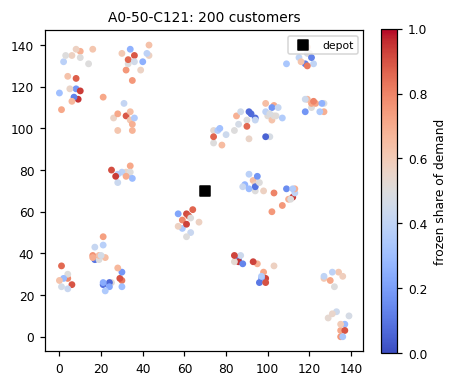

In [5]:
inst = load_instance(f"{DATA}/Instances/200 customers/A0-50-C121.txt")
fig, ax = plt.subplots(figsize=(4.2, 4)); P.plot_instance(inst, ax); plt.tight_layout(); plt.show()

## 2. Validation against the published results
For every published route solution whose instance file is also published, we audit feasibility independently (time windows, $T_{max}$, capacities, frigoboxes, one route per physical vehicle) and recompute the objective.

In [6]:
refs = A.published_references(DATA)
refs["diff"] = refs["ref_cost"] - refs["ref_reported"]
print(f"{len(refs)} published solutions checked")
print("max |recomputed - reported|:", round(float(refs["diff"].abs().max()), 3))
print("within 0.06:", int((refs["diff"].abs() <= 0.06).sum()))
refs[refs["diff"].abs() > 0.06]

74 published solutions checked
max |recomputed - reported|: 0.998
within 0.06: 73


,instance,ref_cost,ref_reported,ref_vehicles,ref_distance,diff
8,A0-10-R127,2527.822204,2528.82,2,527.433316,-0.997796


All but one agree to rounding; A0-10-R127 is reported exactly 1.0 above the cost of its own routes. Differences between the paper of [1] and its published code are documented in `docs/DEVIATIONS.md`.

## 3. Methods
All methods share the multi-start VNS of [1]: random construction, shaking, vehicle assignment (SelectBestVehicle), local search (2-opt, relocate, 2-opt*, remove-two-insert-one) and Cauchy annealing acceptance $\beta<T^2/(T^2+\Delta E^2)$. **They differ only in the shaking step.** Every per-step policy gets 20 shaking steps per restart, the nominal budget of the sweep of [1].

**Experiment 1: which neighborhood?** Actions $N_1$ swap, $N_2$ relocate, $N_3$ segment shift, $N_4$ remove-insert.

| label | policy |
|---|---|
| `ms-vns` | [1]: sweep $N_1\to N_4$, 5 attempts each; order re-sorted every 100 restarts by scores (1, 0, 5) |
| `vns-random` | uniform random neighborhood |
| `q-vns` | tabular Q-learning over the 4 neighborhoods |
| `vns-n4` | $N_4$ only |

**Experiment 2: which destroy-and-repair operator?** Every shaking step is a remove–insert move. The action is one of 8 pairs (removal $\in$ {random, worst, related, route}) × (insertion $\in$ {greedy, regret-2}).

| label | policy |
|---|---|
| `ops-random` | uniform random pair |
| `ops-alns` | ALNS roulette wheel (Ropke & Pisinger 2006): scores (33, 9, 13), reaction 0.1, segments of 100 steps |
| `ops-q` | **ours**: tabular Q-learning; state = (last outcome, stagnation, search phase), 27 states × 8 actions |

**Q-learning.** Rewards are 5 / 2 / 0.5 / 0 / −1 for new best / improved / accepted / rejected / infeasible. The update is $Q(s,a)\leftarrow Q(s,a)+\alpha\,[r+\gamma\max_{a'}Q(s',a')-Q(s,a)]$, with the last step of a restart treated as terminal, $\alpha=0.1$, $\gamma=0.9$, and $\varepsilon$-greedy exploration with $\varepsilon$ decaying linearly from 0.3 to 0.05 over the time budget.

## 4. One instance, step by step
The baseline of [1] and our method on A0-50-C121, 30 s each.

ms-vns  cost= 36866.11  vehicles=32  distance= 4865.6  gap to [1]=  8.45%  feasible=True
ops-q   cost= 27674.95  vehicles=24  distance= 3674.7  gap to [1]=-18.59%  feasible=True
published solution of [1]: 33994.51


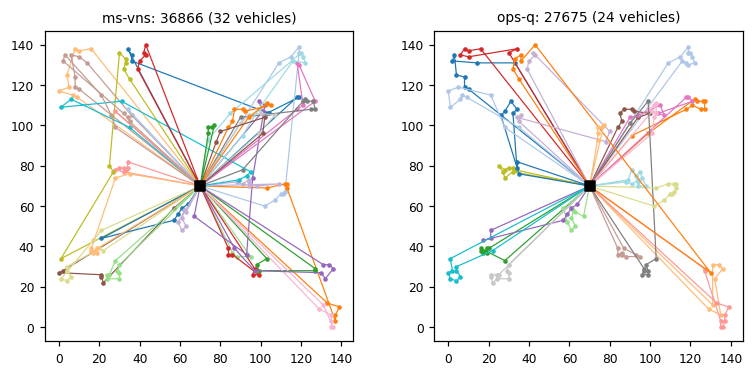

In [7]:
demo = {alg: run(inst, alg, 30) for alg in ["ms-vns", "ops-q"]}
ref = refs.set_index("instance").loc[inst.name, "ref_cost"]
for alg, r in demo.items():
    print(f"{alg:7s} cost={r.best_cost:9.2f}  vehicles={r.vehicles}  distance={r.distance:7.1f}  "
          f"gap to [1]={100 * (r.best_cost - ref) / ref:6.2f}%  feasible={r.feasible}")
print(f"published solution of [1]: {ref:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
for ax, (alg, r) in zip(axes, demo.items()):
    P.plot_routes(inst, r.routes, ax=ax, title=f"{alg}: {r.best_cost:.0f} ({r.vehicles} vehicles)")
plt.tight_layout(); plt.show()

## 5. Experiment 1: learned neighborhood selection (diagnosis)
Pilot: 6 instances (one per family), 3 seeds, 30 s. To rerun it:
`python experiments/run.py --data data/MVRDC --instances A0-50-C121 A0-50-R121 A0-50-RC121 A1-50-C221 A2-50-R221 A2-50-RC221 --algorithms ms-vns vns-random q-vns vns-n4 --seeds 1-3 --time-limit 30 --workers 2 --out results/pilot`

In [8]:
res1 = A.add_gaps(A.load_results("results/pilot"), refs)
res1 = res1[res1["algorithm"].isin(["ms-vns", "vns-random", "q-vns", "vns-n4"])]
display(A.summary_table(res1)[["algorithm", "instances", "best_gap", "avg_gap", "vehicles", "restarts"]])
use1 = A.neighborhood_usage(A.load_runs("results/pilot"))
use1 = use1[use1["algorithm"].isin(["ms-vns", "q-vns"])]
u = use1.groupby(["algorithm", "neighborhood"])[["picks", "infeasible"]].sum()
u["share"] = use1.groupby(["algorithm", "neighborhood"])["share"].mean().round(3)
u["infeasible_%"] = (100 * u["infeasible"] / u["picks"]).round(1)
u[["share", "infeasible_%"]].unstack(0)

,algorithm,instances,best_gap,avg_gap,vehicles,restarts
0,ms-vns,6,2.497,4.949,19.556,250.278
3,vns-random,6,2.173,3.865,19.278,252.111
1,q-vns,6,-4.657,-2.754,18.389,142.556
2,vns-n4,6,-5.355,-4.137,18.222,83.667


share        infeasible_%      
algorithm    ms-vns  q-vns       ms-vns q-vns
neighborhood                                 
N1            0.248  0.055         81.1  76.2
N2            0.249  0.087         56.1  48.9
N3            0.249  0.294         26.7  10.1
N4            0.254  0.564          0.1   0.6

**Reading.** Under the sweep of [1], most $N_1$ (swap) and about half of $N_2$ (relocate) shakes find no feasible move on these tight time windows, yet each neighborhood keeps a quarter of the budget. Re-ordering cannot change that allocation. Q-learning moves effort to $N_3$/$N_4$ and beats [1]'s policy, but simply applying $N_4$ does better still. A neighborhood-level agent has little to decide, which motivates Experiment 2.

## 6. Experiment 2 (main): learned destroy-and-repair operator selection
**Design.** 30 of the 60 instances with 200 customers (every second file: 15 A0, 5 A1, 10 A2), 6 methods, 5 seeds, 60 s per run, which is 900 runs and about **7.5 h** on free Colab (2 cores). Set `USE_DRIVE = True` in Section 0 and `RUN_MAIN = True` here. After a disconnect, run Section 0 and this cell again; finished runs are skipped.

In [9]:
RUN_MAIN = False
MAIN_DIR = f"{RESULTS_ROOT}/main"
if RUN_MAIN:
    !python experiments/run.py --data $DATA --sizes "200 customers" --every 2 \
        --algorithms ms-vns q-vns vns-n4 ops-random ops-alns ops-q --seeds 1-5 \
        --time-limit 60 --workers 2 --out "$MAIN_DIR"

In [10]:
RES2 = results_dir(MAIN_DIR, "results/opt2_pilot")
res2 = A.add_gaps(A.load_results(RES2), refs)
print(len(res2), "runs,", res2["instance"].nunique(), "instances, all feasible:", bool(res2["feasible"].all()))
A.summary_table(res2)

results from: results/opt2_pilot (stored pilot)
72 runs, 6 instances, all feasible: True


,algorithm,instances,best_gap,avg_gap,sd_gap,vehicles,time_to_best,restarts,all_feasible
3,vns-n4,6,-4.906,-4.187,0.787,18.167,15.207,85.889,True
2,ops-random,6,-16.276,-15.461,0.930,16.111,17.033,85.667,True
0,ops-alns,6,-17.439,-16.296,1.192,15.722,20.984,84.444,True
1,ops-q,6,-17.579,-15.583,2.278,15.778,19.271,91.333,True


In [11]:
A.summary_table(res2, by=["family"])[["family", "algorithm", "instances", "best_gap", "avg_gap", "vehicles"]]

,family,algorithm,instances,best_gap,avg_gap,vehicles
3,A0-C,vns-n4,1,-2.200,-1.974,29.000
2,A0-C,ops-random,1,-14.353,-12.902,25.667
0,A0-C,ops-alns,1,-14.920,-14.739,25.000
1,A0-C,ops-q,1,-17.594,-16.417,24.333
7,A0-R,vns-n4,1,3.260,3.577,29.000
6,A0-R,ops-random,1,-7.829,-7.160,26.000
4,A0-R,ops-alns,1,-10.129,-9.524,25.000
5,A0-R,ops-q,1,-11.816,-10.507,24.667
11,A0-RC,vns-n4,1,-1.056,0.264,27.333
10,A0-RC,ops-random,1,-8.516,-8.248,25.000


**Statistical tests.** Paired Wilcoxon signed-rank tests on per-instance mean costs, `ops-q` against each rival (Holm-corrected), and a Friedman test across all methods.

In [12]:
display(A.wins_table(res2, "ops-q"))
sig2 = A.significance(res2, "ops-q")
display(sig2.round(4))
print("Friedman:", sig2.attrs.get("friedman"))

,vs,better,equal,worse
0,ops-alns,3,0,3
1,ops-random,3,0,3
2,vns-n4,6,0,0


,vs,n_instances,median_diff,mean_diff,W,p,p_holm
0,vns-n4,6,-2449.4287,-2835.4240,0.0,0.0312,0.0938
1,ops-random,6,-299.0688,-330.3492,6.0,0.4375,0.8750
2,ops-alns,6,-34.9635,-11.4717,10.0,1.0000,1.0000


Friedman: {'chi2': 11.0, 'p': 0.0117258755784214, 'algorithms': ['ops-alns', 'ops-q', 'ops-random', 'vns-n4'], 'instances': 6}


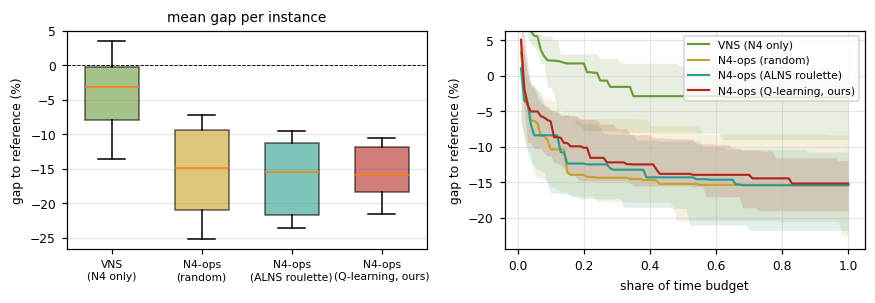

In [13]:
runs2 = A.load_runs(RES2)
conv2 = A.convergence(runs2, refs.set_index("instance")["ref_cost"].to_dict(), np.linspace(0, 1, 101))
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
P.plot_gap_box(res2.groupby(["instance", "algorithm"], as_index=False)["gap"].mean(), ax=axes[0])
axes[0].set_title("mean gap per instance", fontsize=9)
P.plot_convergence(conv2, ax=axes[1]); axes[1].set_ylim(top=conv2[conv2.t >= 0.05]["gap"].quantile(0.99))
plt.tight_layout(); plt.show()

**Which operators are used, and how often do they fail?**

algorithm,ops-alns,ops-q,ops-random
operator,,,
random+greedy,0.122,0.119,0.128
random+regret2,0.146,0.152,0.126
related+greedy,0.114,0.080,0.121
related+regret2,0.148,0.204,0.126
route+greedy,0.102,0.113,0.124
route+regret2,0.110,0.100,0.127
worst+greedy,0.105,0.080,0.125
worst+regret2,0.154,0.151,0.123


algorithm,ops-alns,ops-q,ops-random
operator,,,
random+greedy,17.8,8.3,20.2
random+regret2,0.4,0.3,0.2
related+greedy,19.7,16.5,22.4
related+regret2,2.3,1.8,0.9
route+greedy,38.8,46.0,42.5
route+regret2,34.3,38.7,36.4
worst+greedy,24.3,19.1,29.1
worst+regret2,3.1,5.5,2.7


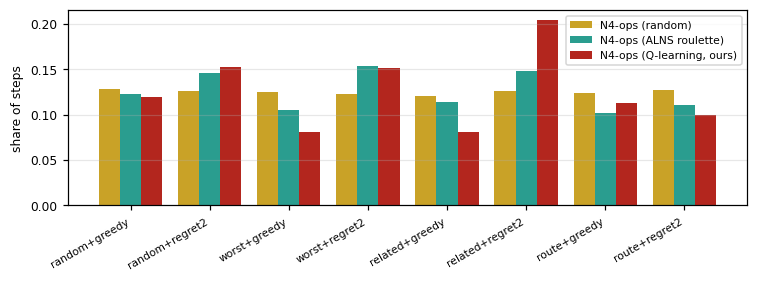

In [14]:
use2 = A.neighborhood_usage([r for r in runs2 if r["algorithm"] in OPS_ALGORITHMS])
use2["operator"] = use2["neighborhood"].str[1:].astype(int).map(lambda h: OP_NAMES[h - 1])
tab = use2.groupby(["algorithm", "operator"]).agg(share=("share", "mean"), picks=("picks", "sum"),
                                                  infeasible=("infeasible", "sum"))
tab["infeasible_%"] = (100 * tab["infeasible"] / tab["picks"]).round(1)
display(tab["share"].unstack(0).round(3))
display(tab["infeasible_%"].unstack(0))
algs = [a for a in OPS_ALGORITHMS if a in tab.index.get_level_values(0)]
fig, ax = plt.subplots(figsize=(7, 2.6)); w = 0.8 / max(1, len(algs))
for k, a in enumerate(algs):
    sh = tab.loc[a, "share"].reindex(OP_NAMES).fillna(0)
    ax.bar(np.arange(len(OP_NAMES)) + k * w, sh.values, w, color=P.COLORS.get(a), label=A.ALG_LABEL.get(a, a))
ax.set_xticks(np.arange(len(OP_NAMES)) + 0.4 - w / 2)
ax.set_xticklabels(OP_NAMES, rotation=30, ha="right", fontsize=7)
ax.set_ylabel("share of steps"); ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**What did the agent learn?** Final Q-values of one run (rows: visited states, encoded as last outcome, stagnation, phase).

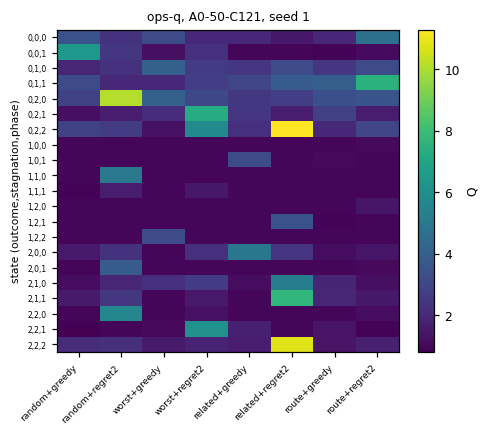

In [15]:
qrun = next(r for r in runs2 if r["algorithm"] == "ops-q")
fig, ax = plt.subplots(figsize=(4.5, 4))
P.plot_q_policy(qrun["selector_stats"]["q_table"], ax=ax, features=("outcome", "stagnation", "phase"))
ax.set_xticks(range(len(OP_NAMES))); ax.set_xticklabels(OP_NAMES, rotation=45, ha="right", fontsize=6)
ax.set_title(f'ops-q, {qrun["instance"]}, seed {qrun["seed"]}', fontsize=8); plt.tight_layout(); plt.show()

## 7. Parameter sensitivity of the Q-learning policy
One parameter at a time is changed around the default ($\alpha=0.1$, $\gamma=0.9$, $\varepsilon_0=0.3$, rewards $(5,2,0.5,0,-1)$), on 6 instances (one per family) × 3 seeds × 60 s. That is 8 variants and about **1.2 h**. The default comes from the main experiment (same instances and seeds).

In [16]:
RUN_SENS = False
SENS_DIR = f"{RESULTS_ROOT}/sens"
SENS_INSTANCES = "A0-50-C121 A0-50-R121 A0-50-RC121 A1-50-C221 A2-50-R221 A2-50-RC221"
SENS_VARIANTS = {
    "alpha=0.05": "alpha=0.05", "alpha=0.3": "alpha=0.3",
    "gamma=0.5": "gamma=0.5", "gamma=0.99": "gamma=0.99",
    "eps=0.1": "eps_start=0.1", "eps=0.5": "eps_start=0.5",
    "reward=best-only": "rewards=[1,0,0,0,0]", "reward=no-penalty": "rewards=[5,2,0.5,0,0]",
}
if RUN_SENS:
    for name, qarg in SENS_VARIANTS.items():
        label = f"ops-q@{name}"
        !python experiments/run.py --data $DATA --instances $SENS_INSTANCES --algorithms ops-q \
            --q "$qarg" --label "$label" --seeds 1-3 --time-limit 60 --workers 2 --out "$SENS_DIR"

In [17]:
if os.path.isdir(f"{SENS_DIR}/runs"):
    sens = A.add_gaps(A.load_results(SENS_DIR), refs)
    base = res2[(res2["algorithm"] == "ops-q") & res2["instance"].isin(SENS_INSTANCES.split())
                & res2["seed"].isin([1, 2, 3])].assign(algorithm="ops-q@default")
    allv = pd.concat([base, sens], ignore_index=True)
    stab = allv.groupby("algorithm").agg(runs=("gap", "size"), avg_gap=("gap", "mean"),
                                        sd_gap=("gap", "std"), vehicles=("vehicles", "mean"))
    stab["diff_vs_default"] = stab["avg_gap"] - stab.loc["ops-q@default", "avg_gap"]
    stab.index = stab.index.str.replace("ops-q@", "", regex=False)
    display(stab.sort_values("avg_gap").round(3))
    s = stab.sort_values("avg_gap")
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.barh(s.index, s["avg_gap"], xerr=s["sd_gap"],
            color=["#b3261e" if i == "default" else "#9aa5b1" for i in s.index])
    ax.set_xlabel("average gap to [1] (%)"); ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("no sensitivity results yet: set RUN_SENS = True above")

no sensitivity results yet: set RUN_SENS = True above


## 8. Small instances: comparison with CPLEX
In [1], CPLEX (4 h limit) proves optimality on all 10-customer instances, and those optima equal the published solutions. A gap of 0 therefore means the optimum was found (5 s per run).

In [18]:
small = []
for p in list_instances(DATA, "10 customers"):
    I = load_instance(p)
    for alg in ["ms-vns", "ops-q"]:
        r = run(I, alg, 5)
        small.append({"instance": I.name, "algorithm": alg, "best_cost": r.best_cost, "feasible": r.feasible})
small = pd.DataFrame(small).merge(refs[["instance", "ref_cost"]], on="instance", how="left")
small["gap"] = 100 * (small["best_cost"] - small["ref_cost"]) / small["ref_cost"]
small.pivot(index="instance", columns="algorithm", values="gap").round(3)

algorithm,ms-vns,ops-q
instance,,
A0-10-C121,-0.000,-0.000
A0-10-C123,-0.000,-0.000
A0-10-C124,-0.000,-0.000
A0-10-C127,NaN,NaN
A0-10-C129,0.008,0.008
A0-10-R121,0.000,0.000
A0-10-R1210,-0.000,-0.000
A0-10-R122,0.009,0.009
A0-10-R126,-0.008,-0.008


## 9. Pros and cons
**Operator portfolio (Experiment 2).**
* Pro: regret-2 insertion and route removal attack the vehicle term of $f(x)$ directly. Regret-2 rarely fails, while greedy insertion often cannot re-insert a removed customer under tight time windows (Section 6, operator table).
* Con: destroy-and-repair steps are expensive, so fewer restarts fit in the budget than with the swap and relocate moves of [1].

**Learned selection (Q-learning) vs. ALNS roulette vs. random.**
* Pro: the agent can condition its choice on the search state (last outcome, stagnation, phase), which the roulette wheel cannot do; no operator weights have to be tuned by hand.
* Con: it needs exploration ($\varepsilon$) and a reward design, and with a short budget it sees few transitions per state. Whether it beats the roulette wheel is decided by the tests in Section 6, not assumed.

**Implementation.** Python is 10–50 times slower than the C++ code of [1]. All methods therefore share the same wall-clock budget and are compared with each other on the same machine, and gaps to [1] are reported for reference only.